In [1]:
# Cloud authentication.
from google.colab import auth
auth.authenticate_user()

In [2]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [4]:
# Folium setup.
import folium
print(folium.__version__)
import pandas as pd

# Define the URL format used for Earth Engine generated map tiles.
EE_TILES = 'https://earthengine.googleapis.com/map/{mapid}/{{z}}/{{x}}/{{y}}?token={token}'

# Tensorflow setup.
import os
# %tensorflow_version 1.x
import tensorflow as tf
print("We working with TF Version = ", tf.__version__)
# tf.enable_eager_execution()

device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
  raise SystemError('GPU device not found')
print('Found GPU at: {}'.format(device_name))

0.18.0
We working with TF Version =  2.17.1
Found GPU at: /device:GPU:0


In [5]:
import cv2
import glob
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from keras.models import Model
from keras.layers import Input, Conv2D, MaxPooling2D, concatenate, Conv2DTranspose, BatchNormalization, Dropout, Lambda, UpSampling2D
from keras.optimizers import Adam
from keras.layers import Activation, MaxPool2D, Concatenate
from IPython.display import Image
import pydot
import graphviz

In [12]:
# General
GOAL_CLASS     = 'fotovoltaica'
VERSION        = '1';
GDRIVE         = 'unet-'+ GOAL_CLASS
FOLDER_TRAIN   = 'train_chips_fotoV3'
FOLDER_TEST    = 'eval_chips_fotoV3'

BASE_PATH      = '/content/drive/MyDrive/'
biomes = 'CAATINGA'
# Exportation Configs

indexBands   = ['B','G','R','N','iia','evi','ri','gli','shape']
BANDS          = indexBands
RESPONSE       = 'supervised'
FEATURES       = BANDS + [RESPONSE]
assetNICFI =  'projects/planet-nicfi/assets/basemaps/americas',
# Specify the size and shape of patches expected by the model.
KERNEL_SIZE  = 256
KERNEL_SHAPE = [KERNEL_SIZE, KERNEL_SIZE]
COLUMNS = [
  tf.io.FixedLenFeature(shape=KERNEL_SHAPE, dtype=tf.float32) for k in FEATURES
]
FEATURES_DICT = dict(zip(FEATURES, COLUMNS))

# Sizes of the training and evaluation datasets.
TRAIN_SIZE = 0
EVAL_SIZE  = 0

# Specify model training parameters.
BATCH_SIZE  = 12
DROPOUT     = 0.3
EPOCHS      = 50
BUFFER_SIZE = 1000
OPTIMIZER   = 'Nadam'
LOSS        = 'BinaryCrossentropy'
METRICS     = ['RootMeanSquaredError','Hinge']

In [13]:
MODEL_DIR = '/content/drive/MyDrive/energias/model'
!ls /content/drive/MyDrive/energias/model

model_03_10_2024.h5	model_20_11_2024.keras	model_ioU_07_12_2024.keras
model_03_10_2024.keras	model_24_10_2024.h5	valores_histogram4L_OiU_07_12.csv
model_07_12_2024.keras	model_24_10_2024.keras
model_10_12_2024.keras	model_26_10_2024.keras


# Training data (Conjunto de Treinamento)

Load the data exported from Earth Engine into a `tf.data.Dataset`.  The following are helper functions for that.

In [15]:
pathDrivetrain =  '/content/drive/MyDrive/' + FOLDER_TRAIN
pathDrivetest =  '/content/drive/MyDrive/' + FOLDER_TEST
print("folder do test ", pathDrivetest)
print("\n ----------- Lista de files TFRecords ----------------")
lstFiles = glob.glob(pathDrivetest + '/*.gz')
print(f"Loading # {len(lstFiles)} files tfrecords in the test folder")
for cc, nameF in enumerate(lstFiles):
  if cc < 4:
    print("   ->   ", nameF)
print("-------" * 13 )

folder do test  /content/drive/MyDrive/eval_chips_fotoV3

 ----------- Lista de files TFRecords ----------------
Loading # 96 files tfrecords in the test folder
   ->    /content/drive/MyDrive/eval_chips_fotoV3/test_fotoV_YY_2024_10_g0_10.tfrecord.gz
   ->    /content/drive/MyDrive/eval_chips_fotoV3/test_fotoV_YY_2024_10_g1_10.tfrecord.gz
   ->    /content/drive/MyDrive/eval_chips_fotoV3/test_fotoV_YY_2024_10_g2_10.tfrecord.gz
   ->    /content/drive/MyDrive/eval_chips_fotoV3/test_fotoV_YY_2024_10_g4_10.tfrecord.gz
-------------------------------------------------------------------------------------------


In [16]:
def parse_tfrecord(example_proto):
    """The parsing function.
    Read a serialized example into the structure defined by FEATURES_DICT.
    Args:
      example_proto: a serialized Example.
    Returns:
      A dictionary of tensors, keyed by feature name.
    """
    print(FEATURES_DICT)
    return tf.io.parse_single_example(example_proto, FEATURES_DICT)



def to_tuple(inputs):
    """Function to convert a dictionary of tensors to a tuple of (inputs, outputs).
    Turn the tensors returned by parse_tfrecord into a stack in HWC shape.
    Args:
      inputs: A dictionary of tensors, keyed by feature name.
    Returns:
      A dtuple of (inputs, outputs).
    """
    # my_label = 1
    inputsList = []
    tmp = None
    for cc, kkey in enumerate(FEATURES):

        if cc < len(BANDS):
            # tmp = (inputs.get(key) - val_mean[cc]) / val_stdDev[cc]
            tmp = inputs.get(kkey)
            tmp = tmp / 10000
            # tmp = tmp.astype(np.float32)
        else:
            tmp = inputs.get(kkey)
            # tmp = tmp.astype(np.float32)
            # val_m = np.max(tmp)
            # if val_m == 0:
            #      my_label = 0
        # print("loadin kkey ", kkey, " with ", tmp.shape)
        inputsList.append(tmp)
    stacked = tf.stack(inputsList, axis=0)
    # Convert from CHW to HWC
    stacked = tf.transpose(stacked, [1, 2, 0])
    print("---- SIZE OF MATRIZ ENDED ------ ", stacked.shape)

    return stacked[:,:,:len(BANDS)], stacked[:,:,len(BANDS):]

def get_dataset(pattern):
    """Function to read, parse and format to tuple a set of input tfrecord files.
    Get all the files matching the pattern, parse and convert to tuple.
    Args:
      pattern: A file pattern to match in a Cloud Storage bucket.
    Returns:
      A tf.data.Dataset
    """
    glob = tf.io.gfile.glob(pattern)
  #   glob = tf.io.gfile.glob(pattern) #https://www.tensorflow.org/api_docs/python/tf/io/gfile/glob
    dataset = tf.data.TFRecordDataset(glob, compression_type='GZIP')
    dataset = dataset.map(parse_tfrecord, num_parallel_calls=5)
    dataset = dataset.map(to_tuple, num_parallel_calls=5)
    return dataset

In [17]:
version_samples_acc = "_v1"
def get_eval_dataset():
	glob = pathDrivetest + '/test_fotoV_YY_*'
	dataset = get_dataset(glob)
	dataset = dataset.shuffle(int(BUFFER_SIZE/2)).batch(BATCH_SIZE).repeat(1)
	return dataset

evaluation = get_eval_dataset()
#print(iter(evaluation.take(1)).next())

{'B': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'G': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'R': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'N': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'iia': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'evi': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'ri': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'gli': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'shape': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'supervised': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)}
---- SIZE OF MATRIZ ENDED ------  (256, 256, 10)


# Model (Algoritmo para Predição)

Here we use the Keras implementation of the U-Net model as found [in the TensorFlow examples](https://github.com/tensorflow/models/blob/master/samples/outreach/blogs/segmentation_blogpost/image_segmentation.ipynb).  The U-Net model takes 256x256 pixel patches as input and outputs per-pixel class probability, label or a continuous output.  We can implement the model essentially unmodified, but will use mean squared error loss on the sigmoidal output since we are treating this as a regression problem, rather than a classification problem.  Since impervious surface fraction is constrained to [0,1], with many values close to zero or one, a saturating activation function is suitable here.

In [11]:
# help(tf.keras.initializers.GlorotNormal())

In [18]:
VERSION = '1'
# modelUNet = get_modelUNetAttention()
EPOCH = 0
keras_MODEL_DIR = MODEL_DIR + '/model_10_12_2024.keras'
print("modelo keras save in => ", keras_MODEL_DIR)
# Recreate the exact same model, including its weights and the optimizer
mUNETtrained = tf.keras.models.load_model(keras_MODEL_DIR)
# Show the model architecture
mUNETtrained.summary()

modelo keras save in =>  /content/drive/MyDrive/energias/model/model_10_12_2024.keras


/usr/local/lib/python3.10/dist-packages/keras/src/saving/saving_lib.py:713: UserWarning: Skipping variable loading for optimizer 'adam', because it has 166 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "U-Net"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)              ┃ Output Shape           ┃        Param # ┃ Connected to           ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)  │ (None, 256, 256, 9)    │              0 │ -                      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d (Conv2D)           │ (None, 256, 256, 64)   │          5,248 │ input_layer[0][0]      │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization       │ (None, 256, 256, 64)   │            256 │ conv2d[0][0]           │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation (Activation)   │ (None, 256, 256, 64)   │              0 │ batch_normalization[0… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_1 (Conv2D)         │ (None, 256, 256, 64)   │         36,928 │ activation[0][0]       │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_1     │ (None, 256, 256, 64)   │            256 │ conv2d_1[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_1 (Activation) │ (None, 256, 256, 64)   │              0 │ batch_normalization_1… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d             │ (None, 128, 128, 64)   │              0 │ activation_1[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_2 (Conv2D)         │ (None, 128, 128, 128)  │         73,856 │ max_pooling2d[0][0]    │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_2     │ (None, 128, 128, 128)  │            512 │ conv2d_2[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_2 (Activation) │ (None, 128, 128, 128)  │              0 │ batch_normalization_2… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_3 (Conv2D)         │ (None, 128, 128, 128)  │        147,584 │ activation_2[0][0]     │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_3     │ (None, 128, 128, 128)  │            512 │ conv2d_3[0][0]         │
│ (BatchNormalization)      │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ activation_3 (Activation) │ (None, 128, 128, 128)  │              0 │ batch_normalization_3… │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ max_pooling2d_1           │ (None, 64, 64, 128)    │              0 │ activation_3[0][0]     │
│ (MaxPooling2D)            │                        │                │                        │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ conv2d_4 (Conv2D)         │ (None, 64, 64, 256)    │        295,168 │ max_pooling2d_1[0][0]  │
├───────────────────────────┼────────────────────────┼────────────────┼────────────────────────┤
│ batch_normalization_4

 Total params: 93,152,709 (355.35 MB)

 Trainable params: 31,046,977 (118.43 MB)

 Non-trainable params: 11,776 (46.00 KB)

 Optimizer params: 62,093,956 (236.87 MB)

In [19]:
# quer validar o modelo ?
avaliar = False
csvsaved = True

In [20]:
# Re-evaluate the model
if avaliar:
    result = mUNETtrained.evaluate(evaluation)
    print(" os valores de accuracia = ", result)

In [23]:
dfHist = None
try:
    pathCSV = '/content/drive/MyDrive/energias/registros/valores_accuracy_histogram_10_12.csv'
    dfHist = pd.read_csv(pathCSV)
    dfHist.head()

except:
    csvsaved = False

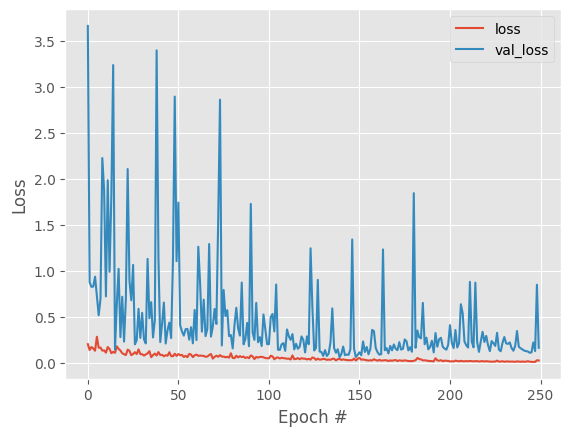

In [ ]:
# plot the training loss and accuracy
plt.style.use("ggplot")
if csvsaved:
    epochs_range = range(dfHist['accuracy'].shape[0])
    plt.figure(dfHist=(18,7))
    plt.subplot(1,2,1)
    plt.plot(epochs_range, dfHist['accuracy'], label = 'Training accuracy')
    plt.plot(epochs_range, dfHist['val_accuracy'], label = 'Validation accuracy')
    plt.title('accuracy')
    plt.legend()
    plt.subplot(1,2,2)
    plt.plot(epochs_range, dfHist['loss'], label = 'Training Loss')
    plt.plot(epochs_range, dfHist['val_loss'], label = 'Validation Loss')
    plt.title('Loss')
    plt.xlabel('Epochs')
    plt.ylabel('Value')
    plt.legend()
    plt.show()

# Visualizar dataset of Patchs



In [24]:
tf_record_test = iter(evaluation.take(1)).next()
img_test_lst = tf_record_test[0]
label_test_lst = tf_record_test[1]
print("Size of matriz Imagens dimensions ", img_test_lst.shape)
print("Size of matriz Labels dimensions ", label_test_lst.shape)

Size of matriz Imagens dimensions  (12, 256, 256, 9)
Size of matriz Labels dimensions  (12, 256, 256, 1)


In [25]:
def hex_to_rgb(hex):
    return tuple(int(hex[i:i+2], 16) for i in (0, 2, 4))

def rgb_to_hex(r, g, b):
    return ('{:02X}' * 3).format(r, g, b)

def frame_image(img, frame_width):
    b = frame_width # border size in pixel
    ny, nx = img.shape[0], img.shape[1] # resolution / number of pixels in x and y
    if img.ndim == 3: # rgb or rgba array
        framed_img = np.zeros((b+ny+b, b+nx+b, img.shape[2]))
    elif img.ndim == 2: # grayscale image
        framed_img = np.zeros((b+ny+b, b+nx+b))
    framed_img[b:-b, b:-b] = img
    return framed_img

def convertInt16_to_Int8(myArray):
    nmin = np.min(myArray)
    nmax = np.max(myArray)
    # print("extreme before >> minimo ", nmin, "  |  maximo ", nmax)
    newArray = ((myArray - nmin) / (nmax - nmin)) * 255

    return newArray.astype(np.uint8)


In [26]:
# hex_to_rgb('16212B')

In [27]:
def drawContour(segm, hexcolor):
    # Fill contour "c" with white, make all else black  #fc8d59 (251,141,89)
    colorRGB =  hex_to_rgb(hexcolor[1:])
    segm = np.array(segm)                                             #(rgb(22,33,43))
    ContourR = np.where(segm == 0, colorRGB[0], segm)
    ContourG = np.where(segm == 0, colorRGB[1], segm)
    ContourB = np.where(segm == 0, colorRGB[2], segm)

    imgSeg = np.stack([ContourR,ContourG,ContourB])
    # print(imgSeg.shape)
    imgSeg = np.transpose(imgSeg,[2, 1, 0])

    return imgSeg

loading the first batch 
1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


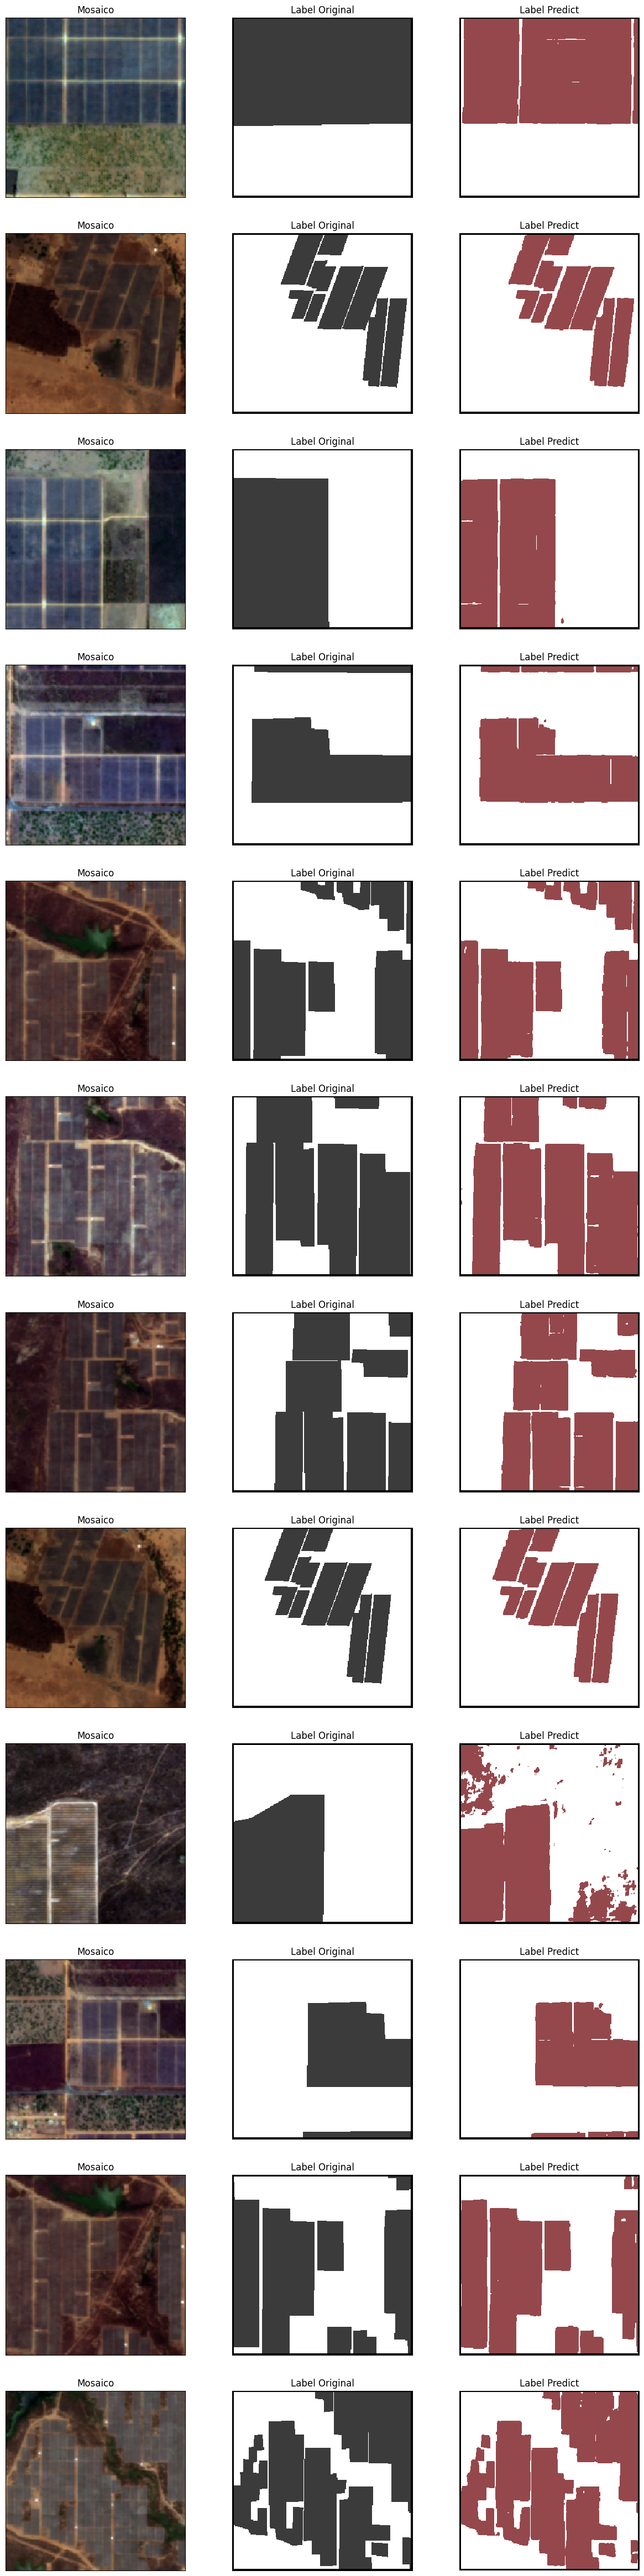

In [28]:
indexBands   = ['B','G','R','N','iia','evi','ri','gli', 'shape']
bandIndex = len(indexBands)
print("loading the first batch ")
fig, ax = plt.subplots(figsize=[15,60], nrows=12, ncols=3)

for ii in range(12):
    bnd_blue = img_test_lst[ii, :, : , 0].numpy() * 10000
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = img_test_lst[ii, :, : , 1].numpy() * 1000
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = img_test_lst[ii, :, : , 2].numpy() * 10000
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))

    imgRGB = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(imgRGB,[2, 1, 0])
    # imgRGB = imgRGB.astype('uint8')
    # imgRGB = convertInt16_to_Int8(imgRGB)
    # print("minimo ", np.min(imgRGB), "   |  maximo ", np.max(imgRGB))

    stackedS = label_test_lst[ii, :, :, 0].numpy()

    # stackedS = np.transpose(stackedS)

    imgtest = img_test_lst[ii, :, : , :].numpy()
    imgtest = imgtest.reshape((1, 256, 256, bandIndex))
    predlabel = mUNETtrained.predict(imgtest)
    # print("shape image predict ",predlabel.shape)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))
    predlabel = predlabel[0,:,:,0]
    predlabel[predlabel < 0.65] = 0
    predlabel[predlabel >= 0.65] = 1
    # predlabel = predlabel.astype(np.uint8)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))

    rgbLabelOri = np.array((1 - stackedS) * 255).astype(np.uint8)
    rgbLabelPred = np.array((1 - predlabel) * 255).astype(np.uint8)
    # print(rgbLabelOri)
    rgbLabelOri = drawContour(rgbLabelOri, '#3b3b3b')
    rgbLabelPred = drawContour(rgbLabelPred, '#94484c')
    rgbLabelOri = frame_image(rgbLabelOri, 2)
    rgbLabelPred = frame_image(rgbLabelPred, 2)
    #tf.contrib.summary.image(str(epoch)+" ->Input/"+str(counter), stacked[0:3], step=0)
    # print(rgbLabelOri)

    # show original image
    ax[ii, 0].set_title('Mosaico', fontsize = 12)
    ax[ii, 0].imshow(imgRGB,interpolation='nearest',vmin=0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB
    # ax[ii, 0].imshow(cv2.cvtColor(imgRGB, cv2.COLOR_BGR2RGB), interpolation='none', vmin=24, vmax=250) # interpolation='nearest',
    ax[ii, 0].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 0].yaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].set_title('Label Original', fontsize = 12)
    ax[ii, 1].imshow(rgbLabelOri.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    ax[ii, 1].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].yaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 2].set_title('Label Predict', fontsize = 12)
    ax[ii, 2].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  # interpolation='nearest',
    ax[ii, 2].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 2].yaxis.set_major_locator(ticker.NullLocator())

plt.axis("off")
plt.show()

# Visualizar predict com o conjunto de treinamento

In [29]:
def get_training_dataset():
	"""Get the preprocessed training dataset
  Returns:
    A tf.data.Dataset of training data.
  """
	pathtrain = pathDrivetrain + '/train_fotoV_YY_*'
	print(f" --- {pathtrain} -------")
	dataset = get_dataset(pathtrain)
	dataset = dataset.shuffle(int(BUFFER_SIZE /2)).batch(BATCH_SIZE).repeat()
	return dataset

training = get_training_dataset()

 --- /content/drive/MyDrive/train_chips_fotoV3/train_fotoV_YY_* -------
{'B': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'G': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'R': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'N': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'iia': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'evi': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'ri': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'gli': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'shape': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None), 'supervised': FixedLenFeature(shape=[256, 256], dtype=tf.float32, default_value=None)}
---- SIZE OF MATRIZ ENDED ------  (256, 256, 10)


In [67]:
tf_record_train = iter(training.take(1)).next()
img_train_lst = tf_record_train[0]
label_train_lst = tf_record_train[1]
print("Size of matriz Imagens dimensions ", img_train_lst.shape)

Size of matriz Imagens dimensions  (12, 256, 256, 9)


loading the first batch 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


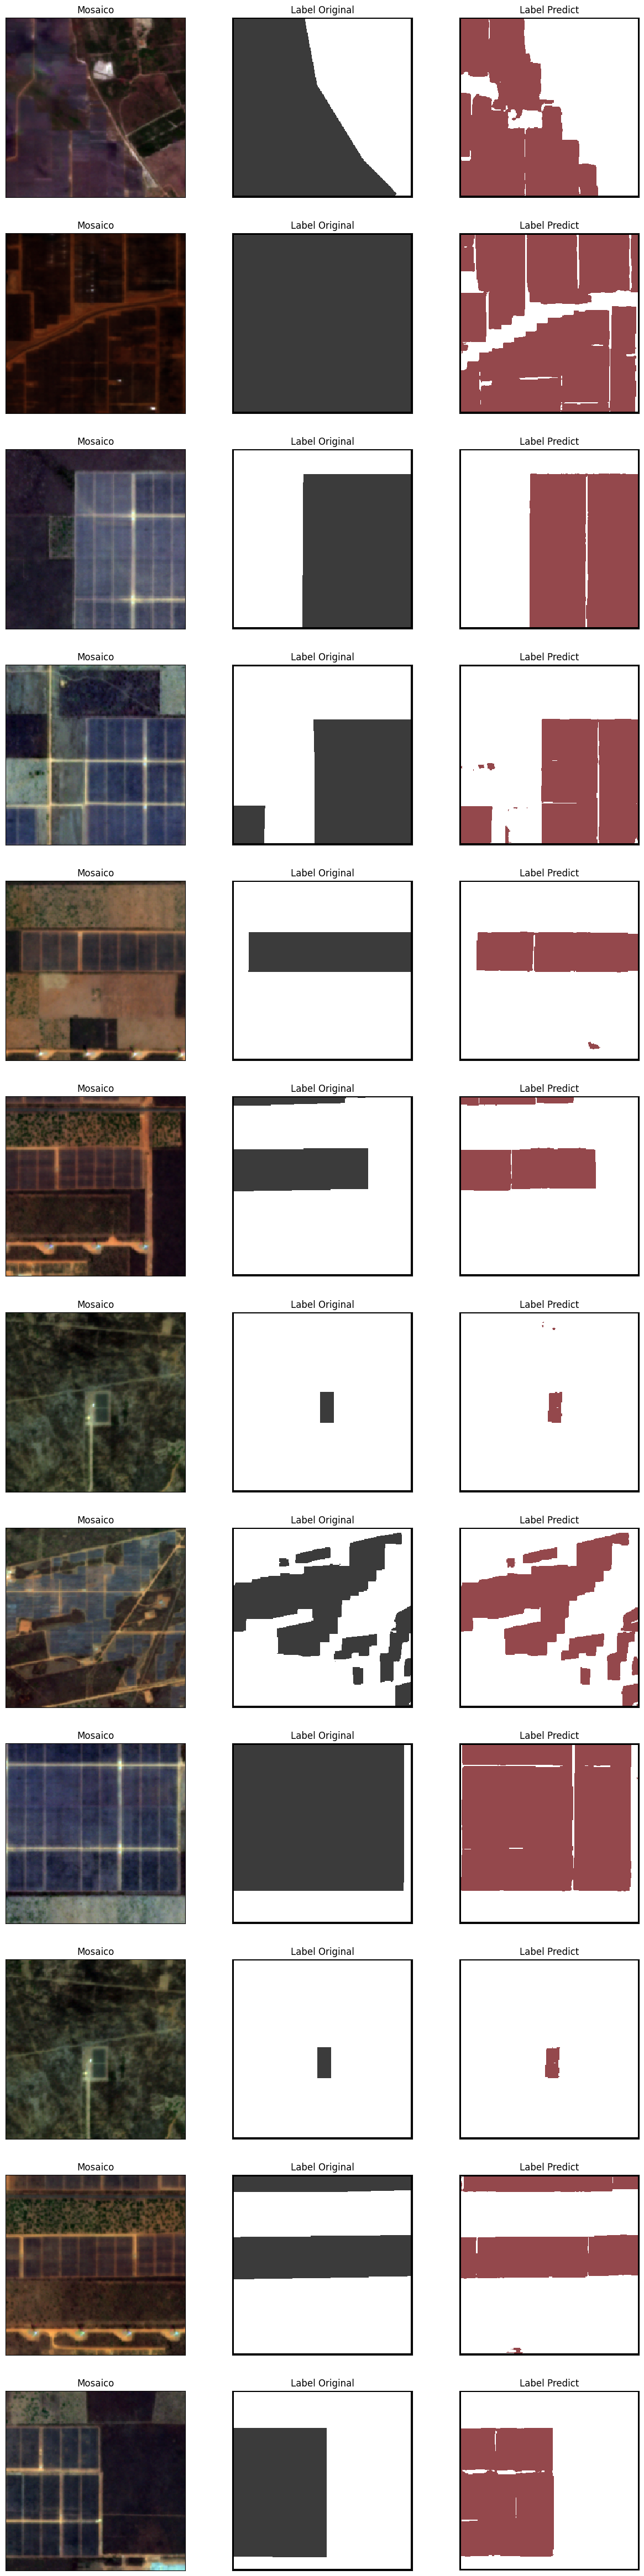

In [68]:
indexBands   = ['B','G','R','N','iia','evi','ri','gli', 'shape']
bandIndex = len(indexBands)
print("loading the first batch ")
fig, ax = plt.subplots(figsize=[15,60], nrows=12, ncols=3)

for ii in range(12):
    bnd_blue = img_train_lst[ii, :, : , 0].numpy() * 10000
    bnd_blue = convertInt16_to_Int8(bnd_blue.astype(np.uint16))
    bnd_green = img_train_lst[ii, :, : , 1].numpy() * 1000
    bnd_green = convertInt16_to_Int8(bnd_green.astype(np.uint16))
    bnd_red = img_train_lst[ii, :, : , 2].numpy() * 10000
    bnd_red = convertInt16_to_Int8(bnd_red.astype(np.uint16))


    imgRGB = np.stack([bnd_red, bnd_green, bnd_blue])
    imgRGB = np.transpose(imgRGB,[2, 1, 0])
    # print("minimo ", np.min(imgRGB), "   |  maximo ", np.max(imgRGB))

    stackedS = label_train_lst[ii, :, :, 0].numpy()
    # stackedS = np.transpose(stackedS)

    imgtrain = img_train_lst[ii, :, : , :].numpy()
    imgtrain = imgtrain.reshape((1,256,256, bandIndex))
    predlabel = mUNETtrained.predict(imgtrain)
    # print("shape image predict ",predlabel.shape)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))
    predlabel = predlabel[0,:,:,0]
    predlabel[predlabel < 0.5] = 0
    predlabel[predlabel >= 0.5] = 1
    predlabel = predlabel.astype(np.int8)
    # print("Minimo imgTest ", np.min(predlabel))
    # print("Maximo imgTest ", np.max(predlabel))

    rgbLabelOri = np.array((1 - stackedS) * 255).astype(np.uint8)
    rgbLabelPred = np.array((1 - predlabel) * 255).astype(np.uint8)
    # print(rgbLabelOri)
    rgbLabelOri = drawContour(rgbLabelOri, '#3b3b3b')
    rgbLabelPred = drawContour(rgbLabelPred, '#94484c')
    rgbLabelOri = frame_image(rgbLabelOri, 2)
    rgbLabelPred = frame_image(rgbLabelPred, 2)
    #tf.contrib.summary.image(str(epoch)+" ->Input/"+str(counter), stacked[0:3], step=0)

    # show original image
    ax[ii, 0].set_title('Mosaico', fontsize = 12)
    ax[ii, 0].imshow(imgRGB,interpolation='nearest',vmin=0, vmax=250) # interpolation='nearest', , interpolation='none', vmin=24, vmax=250, , cv2.COLOR_BGR2RGB
    # ax[ii, 0].imshow(cv2.cvtColor(imgRGB, cv2.COLOR_BGR2RGB), interpolation='none', vmin=24, vmax=250) # interpolation='nearest',
    ax[ii, 0].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 0].yaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].set_title('Label Original', fontsize = 12)
    ax[ii, 1].imshow(rgbLabelOri.astype('uint8'), interpolation='none', vmin=0, vmax=255)  #interpolation='nearest',
    ax[ii, 1].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 1].yaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 2].set_title('Label Predict', fontsize = 12)
    ax[ii, 2].imshow(rgbLabelPred.astype('uint8'), interpolation='none', vmin=0, vmax=255)  # interpolation='nearest',
    ax[ii, 2].xaxis.set_major_locator(ticker.NullLocator())
    ax[ii, 2].yaxis.set_major_locator(ticker.NullLocator())

plt.axis("off")
plt.show()